
Potential outliers (|Z-score| >= 2):
participant_code snippet_id  difficulty_1to10  snippet_mean  deviation  z_score
             705       S007              10.0        3.0125     6.9875 3.048722
             620       S007              10.0        3.0125     6.9875 3.048722
            4873       S007              10.0        3.0125     6.9875 3.048722
             620       S001              10.0        2.5500     7.4500 2.855350
            4873       S001              10.0        2.5500     7.4500 2.855350
             705       S001              10.0        2.5500     7.4500 2.855350
             705       S008              10.0        2.7875     7.2125 2.851590
             620       S008              10.0        2.7875     7.2125 2.851590
            4873       S008              10.0        2.7875     7.2125 2.851590
             705       S002              10.0        2.5625     7.4375 2.840312
             620       S002              10.0        2.5625     7.4375 2.840312
  

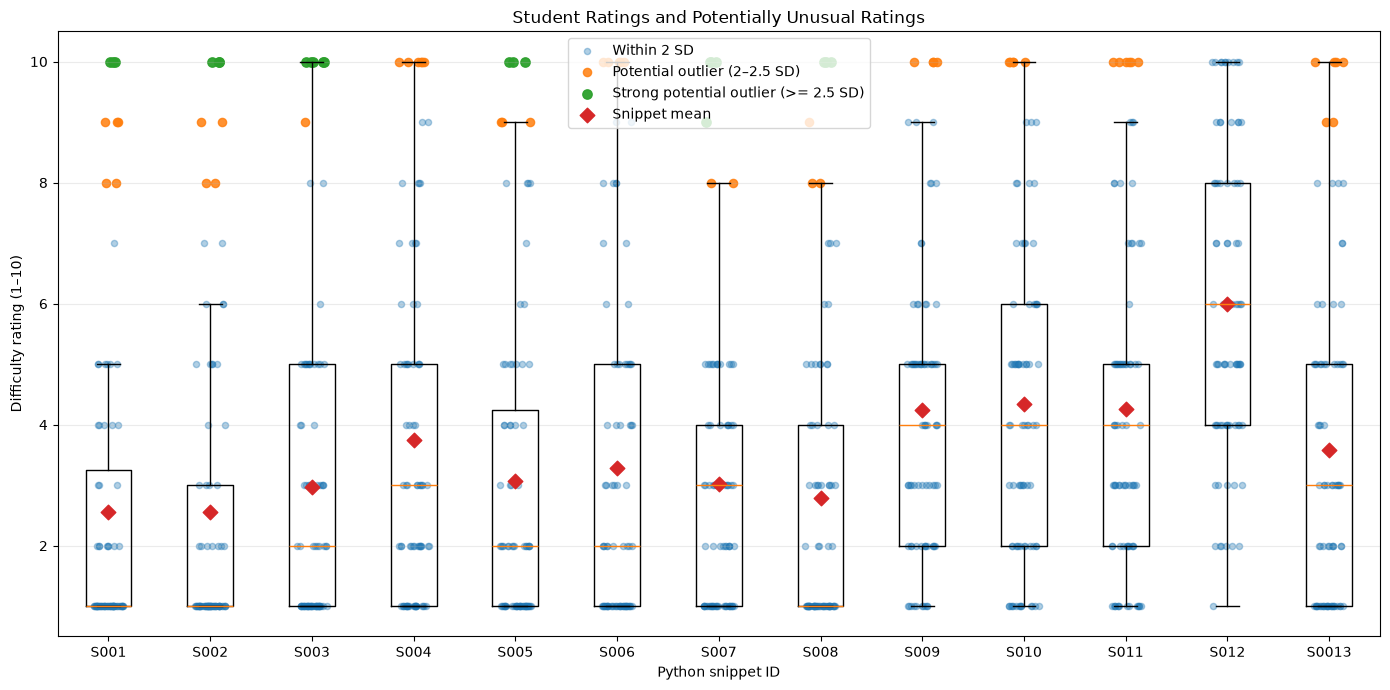

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------

df = pd.read_csv("real_cleaned_dataset.csv")

# Convert difficulty ratings to numeric
df["difficulty_1to10"] = pd.to_numeric(
    df["difficulty_1to10"], errors="coerce"
)

# Remove rows without a difficulty rating for this analysis
df = df.dropna(subset=["difficulty_1to10"]).copy()

# --------------------------------------------------
# 2. Calculate statistics for each snippet
# --------------------------------------------------

# Compare each rating with the other students' ratings
# for the SAME snippet.

df["snippet_mean"] = (
    df.groupby("snippet_id")["difficulty_1to10"]
    .transform("mean")
)

df["snippet_sd"] = (
    df.groupby("snippet_id")["difficulty_1to10"]
    .transform("std")
)

# Difference between the student's rating and the mean
df["deviation"] = (
    df["difficulty_1to10"] - df["snippet_mean"]
)

# Standardized deviation (Z-score)
df["z_score"] = (
    df["deviation"] / df["snippet_sd"].replace(0, np.nan)
)

df["absolute_z"] = df["z_score"].abs()

# Flag potential outliers
df["potential_outlier"] = df["absolute_z"] >= 2
df["strong_outlier"] = df["absolute_z"] >= 2.5

# --------------------------------------------------
# 3. Display potentially noisy ratings
# --------------------------------------------------

columns_to_show = [
    "participant_code",
    "snippet_id",
    "difficulty_1to10",
    "snippet_mean",
    "deviation",
    "z_score"
]

potential_noise = df[df["potential_outlier"]].copy()

potential_noise = potential_noise.sort_values(
    "absolute_z", ascending=False
)

print("\nPotential outliers (|Z-score| >= 2):")
print(potential_noise[columns_to_show].to_string(index=False))

strong_noise = df[df["strong_outlier"]].copy()

print("\nStrong potential outliers (|Z-score| >= 2.5):")
print(strong_noise[columns_to_show].to_string(index=False))

print("\nTotal ratings analysed:", len(df))
print("Potential outliers:", len(potential_noise))
print("Strong potential outliers:", len(strong_noise))

# Save results
potential_noise[columns_to_show].to_csv(
    "potentially_noisy_ratings.csv", index=False
)

strong_noise[columns_to_show].to_csv(
    "strong_potentially_noisy_ratings.csv", index=False
)

# --------------------------------------------------
# 4. Plot ratings for each snippet
# --------------------------------------------------

snippet_order = sorted(
    df["snippet_id"].unique(),
    key=lambda s: (s == "S0013", int(s[1:]) if s[1:].isdigit() else 999)
)

position = {
    snippet: i for i, snippet in enumerate(snippet_order)
}

# Small horizontal jitter prevents overlapping points
rng = np.random.default_rng(42)

x_values = np.array([
    position[s] for s in df["snippet_id"]
], dtype=float)

x_jittered = x_values + rng.uniform(
    -0.15, 0.15, size=len(df)
)

normal = df["absolute_z"] < 2
potential = (df["absolute_z"] >= 2) & (df["absolute_z"] < 2.5)
strong = df["absolute_z"] >= 2.5

fig, ax = plt.subplots(figsize=(14, 7))

# Boxplots show the distribution of ratings for each snippet
for i, snippet in enumerate(snippet_order):
    ratings = df.loc[
        df["snippet_id"] == snippet, "difficulty_1to10"
    ]

    ax.boxplot(
        ratings,
        positions=[i],
        widths=0.45,
        showfliers=False
    )

# Ordinary ratings
ax.scatter(
    x_jittered[normal],
    df.loc[normal, "difficulty_1to10"],
    alpha=0.35,
    s=20,
    label="Within 2 SD"
)

# Potential outliers
ax.scatter(
    x_jittered[potential],
    df.loc[potential, "difficulty_1to10"],
    alpha=0.85,
    s=35,
    label="Potential outlier (2–2.5 SD)"
)

# Strong potential outliers
ax.scatter(
    x_jittered[strong],
    df.loc[strong, "difficulty_1to10"],
    alpha=0.95,
    s=45,
    label="Strong potential outlier (>= 2.5 SD)"
)

# Mean rating for each snippet
means = (
    df.groupby("snippet_id")["difficulty_1to10"]
    .mean()
    .reindex(snippet_order)
)

ax.scatter(
    range(len(snippet_order)),
    means.values,
    marker="D",
    s=55,
    label="Snippet mean"
)

ax.set_xticks(range(len(snippet_order)))
ax.set_xticklabels(snippet_order)

ax.set_xlabel("Python snippet ID")
ax.set_ylabel("Difficulty rating (1–10)")
ax.set_title("Student Ratings and Potentially Unusual Ratings")
ax.set_ylim(0.5, 10.5)

ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()

# Save the plot
plt.savefig(
    "noisy_ratings_by_snippet.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()
